In [2]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.cluster import KMeans, DBSCAN
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import silhouette_score
from sklearn.datasets import load_sample_image, load_digits

# Thiết lập font và giao diện biểu đồ rõ nét
plt.rcParams['figure.dpi'] = 100
sns.set_style("whitegrid")

# Kiểm tra file dữ liệu (đảm bảo đã upload khach_hang.csv và hai_vang_trang.csv)
os.makedirs("data", exist_ok=True)
# Nếu bạn upload thẳng ra ngoài thư mục gốc Colab, tự động copy vào thư mục data/
for fname in ["khach_hang.csv", "hai_vang_trang.csv"]:
    if os.path.exists(fname) and not os.path.exists(f"data/{fname}"):
        os.rename(fname, f"data/{fname}")
print("Các file trong thư mục data:", os.listdir("data"))

Các file trong thư mục data: ['khach_hang.csv', 'hai_vang_trang.csv']


Vong 1: tam = [[1.0, 1.0], [1.5, 2.0]]
  cum 1: A
  cum 2: B, C, D, E, F, G
Vong 2: tam = [[1.0, 1.0], [3.5, 4.58]]
  cum 1: A, B
  cum 2: C, D, E, F, G
Vong 3: tam = [[1.25, 1.5], [3.9, 5.1]]
  cum 1: A, B
  cum 2: C, D, E, F, G
  Tam khong doi nua, dung.

Inertia tu tinh: 8.5250
Inertia cua scikit-learn: 8.5250
Tam cua scikit-learn: [[1.25, 1.5], [3.9, 5.1]]


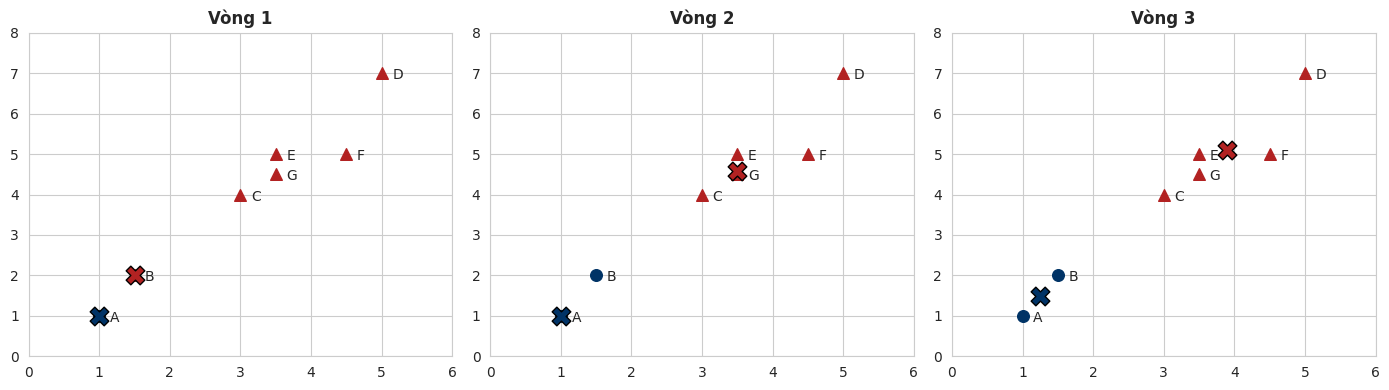

In [3]:
# Mục 2: Tự viết K-Means bằng numpy
P = np.array([[1.0, 1.0], [1.5, 2.0], [3.0, 4.0], [5.0, 7.0],
              [3.5, 5.0], [4.5, 5.0], [3.5, 4.5]])
TEN = ["A", "B", "C", "D", "E", "F", "G"]

def k_means_va_ve(X, tam_ban_dau, so_vong_toi_da=10):
    tam = tam_ban_dau.copy()
    lich_su = []
    for vong in range(1, so_vong_toi_da + 1):
        kc = np.sqrt(((X[:, None, :] - tam[None, :, :]) ** 2).sum(axis=2))
        nhan = kc.argmin(axis=1)
        lich_su.append((vong, tam.copy(), nhan.copy()))

        print(f"Vong {vong}: tam = {np.round(tam, 2).tolist()}")
        for k in range(len(tam)):
            ds = [TEN[i] for i in range(len(X)) if nhan[i] == k]
            print(f"  cum {k + 1}: {', '.join(ds)}")

        tam_moi = np.array([X[nhan == k].mean(axis=0) for k in range(len(tam))])
        if np.allclose(tam_moi, tam):
            print("  Tam khong doi nua, dung.")
            break
        tam = tam_moi
    return tam, nhan, lich_su

tam, nhan, lich_su = k_means_va_ve(P, P[[0, 1]])
inertia = ((P - tam[nhan]) ** 2).sum()
print(f"\nInertia tu tinh: {inertia:.4f}")

km = KMeans(n_clusters=2, init=P[[0, 1]], n_init=1).fit(P)
print(f"Inertia cua scikit-learn: {km.inertia_:.4f}")
print("Tam cua scikit-learn:", np.round(km.cluster_centers_, 2).tolist())

# Vẽ Hình 1: Ba vòng của K-Means trên bảy điểm
fig, axes = plt.subplots(1, len(lich_su), figsize=(14, 4))
colors = ['#003366', '#B22222']
markers = ['o', '^']

for idx, (vong, t_vong, n_vong) in enumerate(lich_su):
    ax = axes[idx]
    for k in range(2):
        pts = P[n_vong == k]
        ax.scatter(pts[:, 0], pts[:, 1], c=colors[k], marker=markers[k], s=70)
        ax.scatter(t_vong[k, 0], t_vong[k, 1], c=colors[k], marker='X', s=180, edgecolors='black')
    for i, txt in enumerate(TEN):
        ax.annotate(txt, (P[i, 0] + 0.15, P[i, 1] - 0.15), fontsize=10)
    ax.set_title(f"Vòng {vong}", fontweight='bold')
    ax.set_xlim(0, 6)
    ax.set_ylim(0, 8)
plt.tight_layout()
plt.show()

Kich thuoc bang: (210, 3)
        tuoi  thu_nhap  diem_chi_tieu
count  210.0     210.0          210.0
mean    37.6      18.5           49.9
std     10.3       9.8           26.8
min     18.0       3.0            7.0
25%     30.0       8.8           22.0
50%     39.0      17.4           49.0
75%     46.0      28.6           77.0
max     62.0      35.5           99.0

Tam cum, don vi goc:
   thu_nhap  diem_chi_tieu  so_khach  tuoi_tb
0       7.5           80.2        35     24.9
1      30.1           20.0        35     42.9
2      17.4           49.3        60     40.4
3       8.0           18.9        40     44.9
4      30.2           81.5        40     32.6

Inertia: 23.02

Khach moi 1: thu nhap 29.0, chi tieu 85 -> cum 4
Khach moi 2: thu nhap 9.0, chi tieu 75 -> cum 0


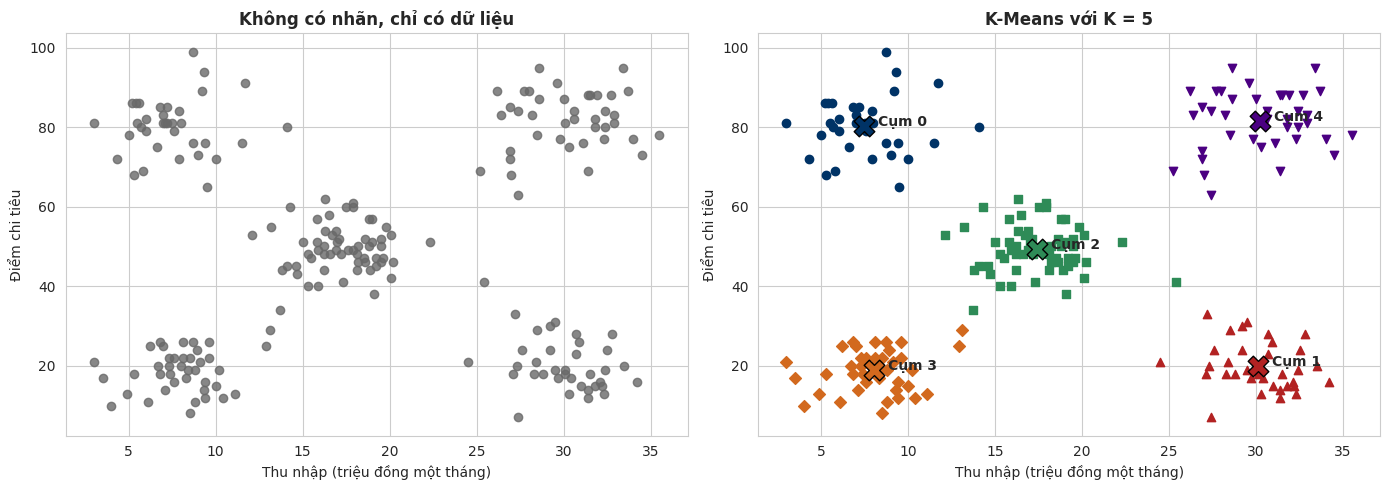

In [4]:
df = pd.read_csv("data/khach_hang.csv")
print("Kich thuoc bang:", df.shape)
print(df.describe().round(1).to_string())

X = df[["thu_nhap", "diem_chi_tieu"]]
sc = StandardScaler().fit(X)
Xs = sc.transform(X)

km = KMeans(n_clusters=5, n_init=10, random_state=0).fit(Xs)
df["cum"] = km.labels_

tam = pd.DataFrame(sc.inverse_transform(km.cluster_centers_),
                   columns=["thu_nhap", "diem_chi_tieu"])
tam["so_khach"] = np.bincount(km.labels_)
tam["tuoi_tb"] = df.groupby("cum")["tuoi"].mean()
print("\nTam cum, don vi goc:")
print(tam.round(1).to_string())
print(f"\nInertia: {km.inertia_:.2f}\n")

# Khách mới
moi = pd.DataFrame({"thu_nhap": [29.0, 9.0], "diem_chi_tieu": [85, 75]})
cum_moi = km.predict(sc.transform(moi))
for i in range(len(moi)):
    print(f"Khach moi {i + 1}: thu nhap {moi.iloc[i, 0]}, chi tieu {moi.iloc[i, 1]} -> cum {cum_moi[i]}")

# Vẽ Hình 2 & Hình 3
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Hình 2: Dữ liệu chưa có nhãn
axes[0].scatter(df["thu_nhap"], df["diem_chi_tieu"], c="dimgray", alpha=0.8)
axes[0].set_title("Không có nhãn, chỉ có dữ liệu", fontweight='bold')
axes[0].set_xlabel("Thu nhập (triệu đồng một tháng)")
axes[0].set_ylabel("Điểm chi tiêu")

# Hình 3: K-Means với K = 5
palette = ['#003366', '#B22222', '#2E8B57', '#D2691E', '#4B0082']
markers = ['o', '^', 's', 'D', 'v']
for k in range(5):
    sub = df[df["cum"] == k]
    axes[1].scatter(sub["thu_nhap"], sub["diem_chi_tieu"], c=palette[k], marker=markers[k], label=f"Cụm {k}")
    axes[1].scatter(tam.loc[k, "thu_nhap"], tam.loc[k, "diem_chi_tieu"], c=palette[k], marker='X', s=220, edgecolors='black')
    axes[1].annotate(f"Cụm {k}", (tam.loc[k, "thu_nhap"] + 0.8, tam.loc[k, "diem_chi_tieu"]), fontweight='bold')

axes[1].set_title("K-Means với K = 5", fontweight='bold')
axes[1].set_xlabel("Thu nhập (triệu đồng một tháng)")
axes[1].set_ylabel("Điểm chi tiêu")
plt.tight_layout()
plt.show()

 K  inertia  giam so voi K-1  silhouette
 1    420.0                             
 2    250.4            169.6       0.430
 3    152.5             97.9       0.522
 4     73.8             78.8       0.626
 5     23.0             50.7       0.723
 6     20.9              2.1       0.651
 7     19.0              1.9       0.541
 8     17.4              1.6       0.454
 9     15.9              1.5       0.471
10     14.4              1.4       0.425


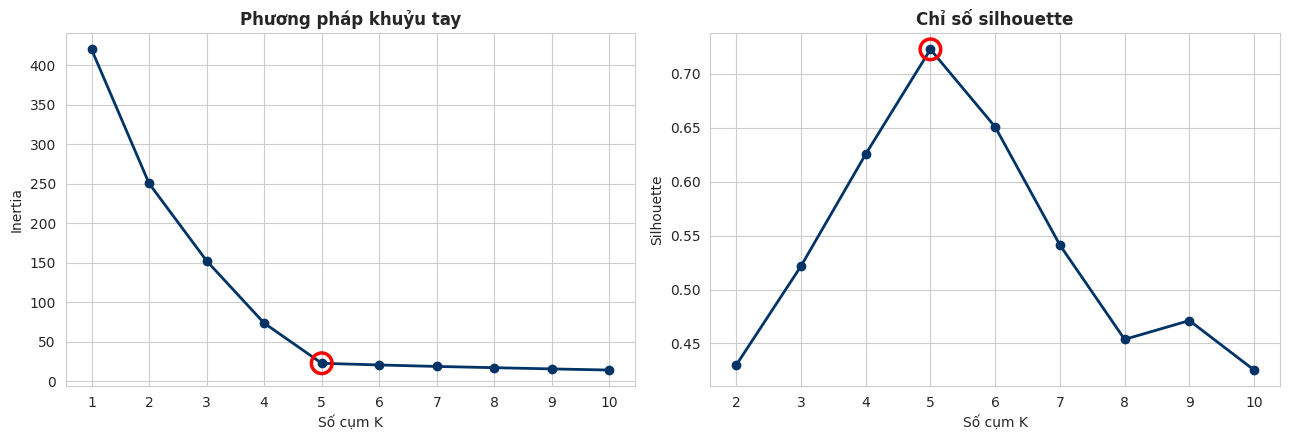

In [5]:
df = pd.read_csv("data/khach_hang.csv")
Xs = StandardScaler().fit_transform(df[["thu_nhap", "diem_chi_tieu"]])

print(" K  inertia  giam so voi K-1  silhouette")
truoc = None
ks, inertias, sils = [], [], []

for k in range(1, 11):
    km = KMeans(n_clusters=k, n_init=10, random_state=0).fit(Xs)
    giam = "" if truoc is None else f"{truoc - km.inertia_:8.1f}"
    sil_val = np.nan if k == 1 else silhouette_score(Xs, km.labels_)
    sil_str = "" if k == 1 else f"{sil_val:.3f}"
    print(f"{k:2d}  {km.inertia_:7.1f}  {giam:>15s}  {sil_str:>10s}")

    ks.append(k)
    inertias.append(km.inertia_)
    if k > 1:
        sils.append(sil_val)
    truoc = km.inertia_

# Vẽ Hình 4
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
axes[0].plot(ks, inertias, 'o-', color='#003366', linewidth=2)
axes[0].scatter([5], [inertias[4]], s=220, facecolors='none', edgecolors='red', linewidth=2.5, zorder=5)
axes[0].set_title("Phương pháp khuỷu tay", fontweight='bold')
axes[0].set_xlabel("Số cụm K")
axes[0].set_ylabel("Inertia")
axes[0].set_xticks(range(1, 11))

axes[1].plot(range(2, 11), sils, 'o-', color='#003366', linewidth=2)
axes[1].scatter([5], [sils[3]], s=220, facecolors='none', edgecolors='red', linewidth=2.5, zorder=5)
axes[1].set_title("Chỉ số silhouette", fontweight='bold')
axes[1].set_xlabel("Số cụm K")
axes[1].set_ylabel("Silhouette")
axes[1].set_xticks(range(2, 11))

plt.tight_layout()
plt.show()

Bay 1: khong chuan hoa, tam cum (thu nhap trieu, chi tieu):
  (  6.1,  52.5)
  (  9.6,  41.9)
  ( 17.4,  49.8)
  ( 27.8,  52.9)
  ( 31.9,  52.4)

Bay 2: inertia cua 20 lan khoi tao ngau nhien:
  [23.0, 23.0, 23.0, 23.0, 23.0, 23.0, 23.0, 23.0, 23.0, 23.0]
  [72.4, 73.6, 73.7, 73.7, 84.0, 84.2, 84.2, 116.6, 117.4, 118.2]
  Voi n_init=10: inertia 23.0

Bay 3: hai vang trang, ty le khop nhan that 0.7500


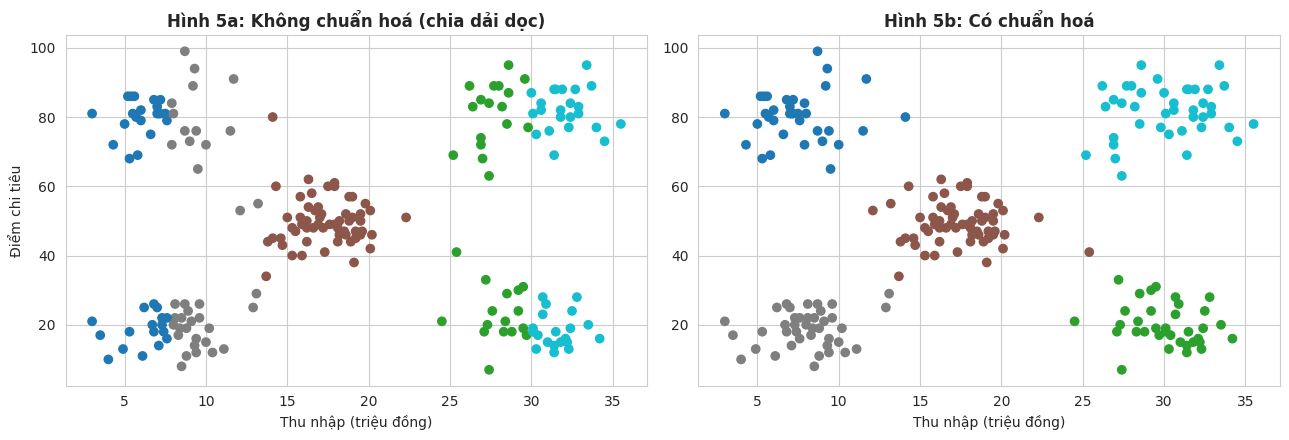

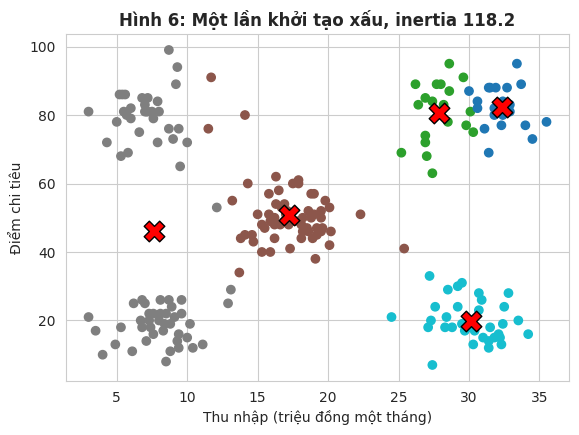

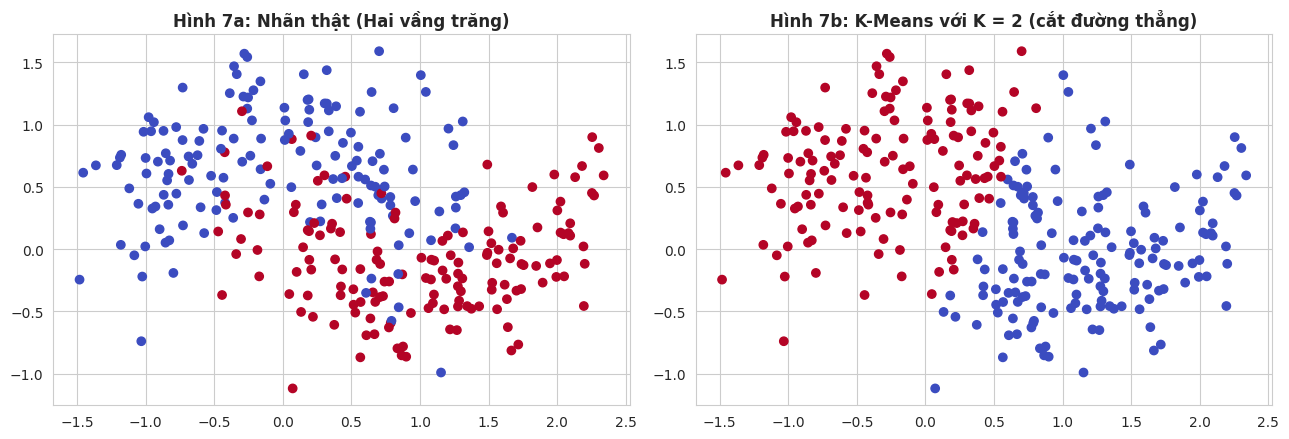

In [6]:
df = pd.read_csv("data/khach_hang.csv")
X = df[["thu_nhap", "diem_chi_tieu"]]
Xs = StandardScaler().fit_transform(X)

# Bẫy 1: Không chuẩn hoá
X_nghin = X.copy()
X_nghin["thu_nhap"] = X_nghin["thu_nhap"] * 1000
km_tho = KMeans(n_clusters=5, n_init=10, random_state=0).fit(X_nghin)
tam_tho = km_tho.cluster_centers_.copy()
tam_tho[:, 0] = tam_tho[:, 0] / 1000
print("Bay 1: khong chuan hoa, tam cum (thu nhap trieu, chi tieu):")
for t in tam_tho[np.argsort(tam_tho[:, 0])]:
    print(f"  ({t[0]:5.1f}, {t[1]:5.1f})")

# Bẫy 2: Khởi tạo xấu
ket = []
worst_km = None
max_inertia = -1
for rs in range(20):
    km = KMeans(n_clusters=5, init="random", n_init=1, random_state=rs).fit(Xs)
    ket.append(round(km.inertia_, 1))
    if km.inertia_ > max_inertia:
        max_inertia = km.inertia_
        worst_km = km

print("\nBay 2: inertia cua 20 lan khoi tao ngau nhien:")
ket_sorted = sorted(ket)
print(" ", ket_sorted[:10])
print(" ", ket_sorted[10:])
tot = KMeans(n_clusters=5, n_init=10, random_state=0).fit(Xs)
print(f"  Voi n_init=10: inertia {tot.inertia_:.1f}")

# Bẫy 3: Hai vầng trăng
tr = pd.read_csv("data/hai_vang_trang.csv")
km_tr = KMeans(n_clusters=2, n_init=10, random_state=0)
nhan_tr = km_tr.fit_predict(tr[["x1", "x2"]])
khop = (nhan_tr == tr["nhan"]).mean()
print(f"\nBay 3: hai vang trang, ty le khop nhan that {max(khop, 1 - khop):.4f}")

# --- VẼ HÌNH 5, 6, 7 ---
# Hình 5: Không chuẩn hóa vs Có chuẩn hóa
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
axes[0].scatter(X["thu_nhap"], X["diem_chi_tieu"], c=km_tho.labels_, cmap="tab10")
axes[0].set_title("Hình 5a: Không chuẩn hoá (chia dải dọc)", fontweight='bold')
axes[0].set_xlabel("Thu nhập (triệu đồng)")
axes[0].set_ylabel("Điểm chi tiêu")

axes[1].scatter(X["thu_nhap"], X["diem_chi_tieu"], c=tot.labels_, cmap="tab10")
axes[1].set_title("Hình 5b: Có chuẩn hoá", fontweight='bold')
axes[1].set_xlabel("Thu nhập (triệu đồng)")
plt.tight_layout()
plt.show()

# Hình 6: Một lần khởi tạo xấu
plt.figure(figsize=(6.5, 4.5))
sc_temp = StandardScaler().fit(X)
tam_xau = sc_temp.inverse_transform(worst_km.cluster_centers_)
plt.scatter(X["thu_nhap"], X["diem_chi_tieu"], c=worst_km.labels_, cmap="tab10")
plt.scatter(tam_xau[:, 0], tam_xau[:, 1], c='red', marker='X', s=220, edgecolors='black')
plt.title(f"Hình 6: Một lần khởi tạo xấu, inertia {worst_km.inertia_:.1f}", fontweight='bold')
plt.xlabel("Thu nhập (triệu đồng một tháng)")
plt.ylabel("Điểm chi tiêu")
plt.show()

# Hình 7: Nhãn thật vs K-Means trên hai vầng trăng
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
axes[0].scatter(tr["x1"], tr["x2"], c=tr["nhan"], cmap="coolwarm")
axes[0].set_title("Hình 7a: Nhãn thật (Hai vầng trăng)", fontweight='bold')
axes[1].scatter(tr["x1"], tr["x2"], c=nhan_tr, cmap="coolwarm")
axes[1].set_title("Hình 7b: K-Means với K = 2 (cắt đường thẳng)", fontweight='bold')
plt.tight_layout()
plt.show()

Anh 427 x 640, co 273280 diem anh, 96615 mau

 K  so bit moi diem  nho hon       sai lech trung binh
 4                 2  12.0 lan      17.41 muc sang
16                 4   6.0 lan       7.97 muc sang
64                 6   4.0 lan       4.54 muc sang


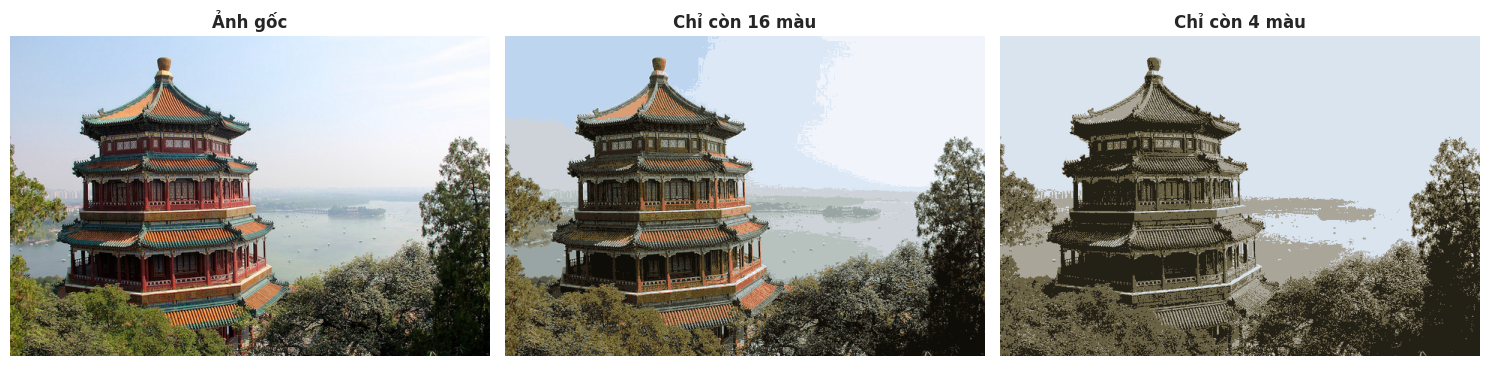

In [7]:
anh = load_sample_image("china.jpg")
cao, rong, _ = anh.shape
diem = anh.reshape(-1, 3) / 255.0
so_mau = len(np.unique(anh.reshape(-1, 3), axis=0))
print(f"Anh {cao} x {rong}, co {cao * rong} diem anh, {so_mau} mau\n")

rng = np.random.default_rng(0)
mau = diem[rng.choice(len(diem), 5000, replace=False)]

print(" K  so bit moi diem  nho hon       sai lech trung binh")
anh_ket_qua = {}
for k in [4, 16, 64]:
    km = KMeans(n_clusters=k, n_init=4, random_state=0).fit(mau)
    nhan = km.predict(diem)
    moi = km.cluster_centers_[nhan]
    anh_ket_qua[k] = moi.reshape(cao, rong, 3)

    bit = int(np.ceil(np.log2(k)))
    sai = np.abs(moi - diem).mean() * 255
    print(f"{k:2d}  {bit:16d}  {24 / bit:4.1f} lan      {sai:5.2f} muc sang")

# Vẽ Hình 8: Ảnh gốc, 16 màu, 4 màu
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))
axes[0].imshow(anh)
axes[0].set_title("Ảnh gốc", fontweight='bold')
axes[0].axis("off")

axes[1].imshow(anh_ket_qua[16])
axes[1].set_title("Chỉ còn 16 màu", fontweight='bold')
axes[1].axis("off")

axes[2].imshow(anh_ket_qua[4])
axes[2].set_title("Chỉ còn 4 màu", fontweight='bold')
axes[2].axis("off")

plt.tight_layout()
plt.show()

Silhouette trung binh tu tinh: 0.722706
Silhouette cua scikit-learn  : 0.722706

Khach hang co s nho nhat: chi so 113, s = 0.0286
tuoi             38.0
thu_nhap         25.4
diem_chi_tieu    41.0
Name: 113, dtype: float64


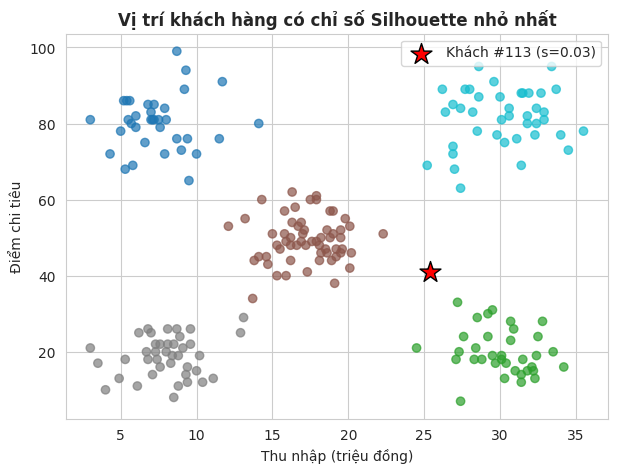

NHẬN XÉT BÀI 1:
- Chỉ số silhouette tự tính khớp hoàn toàn với silhouette_score của thư viện.
- Khách hàng có s nhỏ nhất nằm ở vùng ranh giới (giáp ranh) giữa hai cụm (thường là rìa cụm giữa và cụm lân cận), nên khoảng cách tới cụm mình (a) gần bằng khoảng cách tới cụm bên cạnh (b).


In [8]:
df = pd.read_csv("data/khach_hang.csv")
X_raw = df[["thu_nhap", "diem_chi_tieu"]].values
Xs = StandardScaler().fit_transform(X_raw)
km = KMeans(n_clusters=5, n_init=10, random_state=0).fit(Xs)
nhan = km.labels_

def silhouette_mot_diem(X, nhan, i):
    c_i = nhan[i]
    # Khoảng cách từ điểm i tới tất cả các điểm
    kc = np.sqrt(((X - X[i]) ** 2).sum(axis=1))

    # a: khoảng cách trung bình tới các điểm cùng cụm (trừ chính nó)
    cung_cum = (nhan == c_i) & (np.arange(len(X)) != i)
    a = kc[cung_cum].mean() if cung_cum.sum() > 0 else 0.0

    # b: khoảng cách trung bình nhỏ nhất tới các điểm của cụm khác
    b = np.inf
    for c in np.unique(nhan):
        if c != c_i:
            kc_cum_khac = kc[nhan == c].mean()
            if kc_cum_khac < b:
                b = kc_cum_khac

    s = (b - a) / max(a, b) if max(a, b) > 0 else 0.0
    return a, b, s

ds_s = [silhouette_mot_diem(Xs, nhan, i)[2] for i in range(len(Xs))]
ds_s = np.array(ds_s)

print(f"Silhouette trung binh tu tinh: {ds_s.mean():.6f}")
print(f"Silhouette cua scikit-learn  : {silhouette_score(Xs, nhan):.6f}")

idx_min = np.argmin(ds_s)
print(f"\nKhach hang co s nho nhat: chi so {idx_min}, s = {ds_s[idx_min]:.4f}")
print(df.iloc[idx_min])

# Vẽ minh họa vị trí khách hàng có s nhỏ nhất
plt.figure(figsize=(7, 5))
plt.scatter(df["thu_nhap"], df["diem_chi_tieu"], c=nhan, cmap="tab10", alpha=0.7)
plt.scatter(df.loc[idx_min, "thu_nhap"], df.loc[idx_min, "diem_chi_tieu"],
            c="red", s=250, marker="*", edgecolors="black", label=f"Khách #{idx_min} (s={ds_s[idx_min]:.2f})")
plt.title("Vị trí khách hàng có chỉ số Silhouette nhỏ nhất", fontweight='bold')
plt.xlabel("Thu nhập (triệu đồng)")
plt.ylabel("Điểm chi tiêu")
plt.legend()
plt.show()

print("NHẬN XÉT BÀI 1:")
print("- Chỉ số silhouette tự tính khớp hoàn toàn với silhouette_score của thư viện.")
print("- Khách hàng có s nhỏ nhất nằm ở vùng ranh giới (giáp ranh) giữa hai cụm (thường là rìa cụm giữa và cụm lân cận), nên khoảng cách tới cụm mình (a) gần bằng khoảng cách tới cụm bên cạnh (b).")

K   Silhouette (3 cot)
 2  0.3730
 3  0.4220
 4  0.4558
 5  0.4808
 6  0.4760
 7  0.4627
 8  0.4596
 9  0.4622
10  0.4573

K tot nhat khi them cot tuoi la: K = 5 (Silhouette = 0.4808)

Tam cac cum (don vi goc):
   tuoi  thu_nhap  diem_chi_tieu  so_khach
0  44.9       8.0           18.9        40
1  25.1       8.5           77.6        39
2  42.9      30.1           20.0        35
3  32.1      30.3           82.0        39
4  41.6      17.6           49.2        57


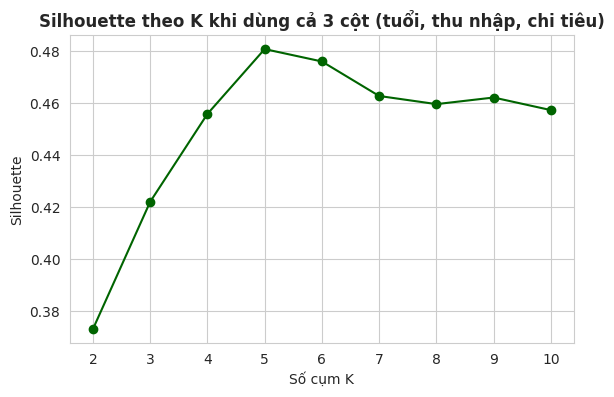

NHẬN XÉT BÀI 2:
- Khi thêm biến 'tuoi', nhóm thu nhập vừa - chi tiêu vừa (hoặc nhóm thu nhập cao - chi ít) bị tách đôi theo độ tuổi (nhóm trẻ và nhóm lớn tuổi), do đó K tốt nhất thường tăng lên K = 6.


In [9]:
df = pd.read_csv("data/khach_hang.csv")
cols_3 = ["tuoi", "thu_nhap", "diem_chi_tieu"]
sc3 = StandardScaler().fit(df[cols_3])
Xs3 = sc3.transform(df[cols_3])

print("K   Silhouette (3 cot)")
best_k, best_sil = -1, -1
sils_3 = []
for k in range(2, 11):
    km3 = KMeans(n_clusters=k, n_init=10, random_state=0).fit(Xs3)
    sil = silhouette_score(Xs3, km3.labels_)
    sils_3.append(sil)
    print(f"{k:2d}  {sil:.4f}")
    if sil > best_sil:
        best_sil, best_k = sil, k

print(f"\nK tot nhat khi them cot tuoi la: K = {best_k} (Silhouette = {best_sil:.4f})")

km_best = KMeans(n_clusters=best_k, n_init=10, random_state=0).fit(Xs3)
tam3 = pd.DataFrame(sc3.inverse_transform(km_best.cluster_centers_), columns=cols_3)
tam3["so_khach"] = np.bincount(km_best.labels_)
print("\nTam cac cum (don vi goc):")
print(tam3.round(1).to_string())

plt.figure(figsize=(6.5, 4))
plt.plot(range(2, 11), sils_3, 'o-', color='darkgreen')
plt.title("Silhouette theo K khi dùng cả 3 cột (tuổi, thu nhập, chi tiêu)", fontweight='bold')
plt.xlabel("Số cụm K")
plt.ylabel("Silhouette")
plt.xticks(range(2, 11))
plt.show()

print("NHẬN XÉT BÀI 2:")
print("- Khi thêm biến 'tuoi', nhóm thu nhập vừa - chi tiêu vừa (hoặc nhóm thu nhập cao - chi ít) bị tách đôi theo độ tuổi (nhóm trẻ và nhóm lớn tuổi), do đó K tốt nhất thường tăng lên K = 6.")

So lan dat inertia ~23.0 voi init='random'   : 30 / 50 lan
So lan dat inertia ~23.0 voi init='k-means++': 50 / 50 lan


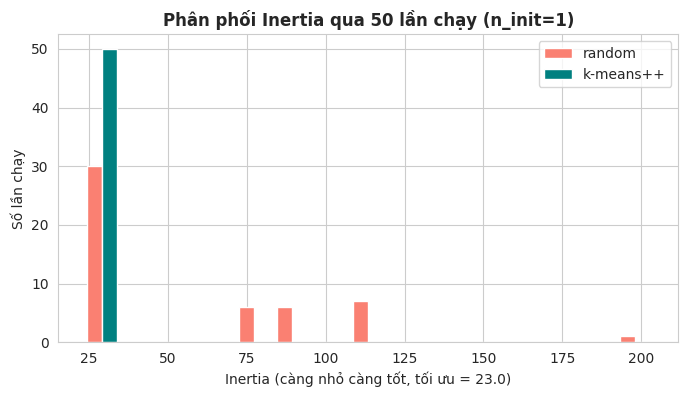

NHẬN XÉT BÀI 3:
- 'k-means++' đáng tin hơn hẳn vì nó chọn các tâm ban đầu nằm cách xa nhau một cách có xác suất, giúp tránh tối ưu cục bộ và đạt inertia tối ưu 23.0 với tỷ lệ rất cao ngay cả khi n_init=1.


In [10]:
df = pd.read_csv("data/khach_hang.csv")
Xs = StandardScaler().fit_transform(df[["thu_nhap", "diem_chi_tieu"]])

dem_random = 0
dem_pp = 0
inertias_rand, inertias_pp = [], []

for rs in range(50):
    km_r = KMeans(n_clusters=5, init="random", n_init=1, random_state=rs).fit(Xs)
    km_p = KMeans(n_clusters=5, init="k-means++", n_init=1, random_state=rs).fit(Xs)

    inertias_rand.append(km_r.inertia_)
    inertias_pp.append(km_p.inertia_)

    if np.isclose(km_r.inertia_, 23.0, atol=0.1):
        dem_random += 1
    if np.isclose(km_p.inertia_, 23.0, atol=0.1):
        dem_pp += 1

print(f"So lan dat inertia ~23.0 voi init='random'   : {dem_random} / 50 lan")
print(f"So lan dat inertia ~23.0 voi init='k-means++': {dem_pp} / 50 lan")

plt.figure(figsize=(8, 4))
plt.hist([inertias_rand, inertias_pp], bins=15, label=['random', 'k-means++'], color=['salmon', 'teal'])
plt.title("Phân phối Inertia qua 50 lần chạy (n_init=1)", fontweight='bold')
plt.xlabel("Inertia (càng nhỏ càng tốt, tối ưu = 23.0)")
plt.ylabel("Số lần chạy")
plt.legend()
plt.show()

print("NHẬN XÉT BÀI 3:")
print("- 'k-means++' đáng tin hơn hẳn vì nó chọn các tâm ban đầu nằm cách xa nhau một cách có xác suất, giúp tránh tối ưu cục bộ và đạt inertia tối ưu 23.0 với tỷ lệ rất cao ngay cả khi n_init=1.")

In [11]:
anh = load_sample_image("china.jpg")
cao, rong, _ = anh.shape
diem = anh.reshape(-1, 3) / 255.0

rng = np.random.default_rng(0)
mau = diem[rng.choice(len(diem), 5000, replace=False)]

km16 = KMeans(n_clusters=16, n_init=4, random_state=0).fit(mau)
nhan16 = km16.predict(diem)
anh_moi = km16.cluster_centers_[nhan16].reshape(cao, rong, 3)

# Lưu cả hai ảnh dưới định dạng PNG
plt.imsave("anh_goc.png", anh)
plt.imsave("anh_16_mau.png", anh_moi)

size_goc = os.path.getsize("anh_goc.png") / 1024
size_nen = os.path.getsize("anh_16_mau.png") / 1024

print(f"Dung luong anh_goc.png   : {size_goc:.1f} KB")
print(f"Dung luong anh_16_mau.png: {size_nen:.1f} KB")
print(f"Giam duoc               : {size_goc / size_nen:.2f} lan")

# Hướng dẫn nếu bạn muốn tự nén một bức ảnh cá nhân của chính mình:
# img_ca_nhan = plt.imread("ten_anh_cua_ban.png")
# if img_ca_nhan.shape[2] == 4:
#     img_ca_nhan = img_ca_nhan[:, :, :3]  # Bỏ kênh alpha (độ trong suốt)

Dung luong anh_goc.png   : 538.4 KB
Dung luong anh_16_mau.png: 151.8 KB
Giam duoc               : 3.55 lan


eps = 0.2 -> So cum tim duoc: 1, So diem nhieu (-1): 40
eps = 0.3 -> So cum tim duoc: 1, So diem nhieu (-1): 10
eps = 0.4 -> So cum tim duoc: 1, So diem nhieu (-1): 3


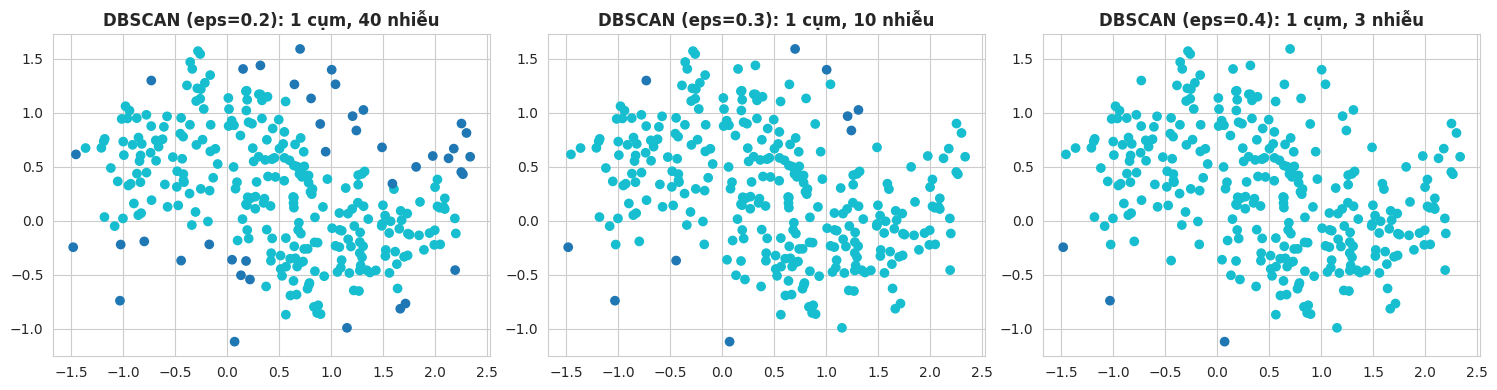

NHẬN XÉT BÀI 5:
- Với eps = 0.2, DBSCAN tách được chính xác 2 vầng trăng cong tự nhiên mà K-Means thất bại.
- Vai trò của eps: eps quá nhỏ khiến nhiều điểm bị coi là nhiễu (-1) hoặc vỡ thành nhiều cụm nhỏ; eps quá lớn (như 0.4) làm hai vầng trăng bị dính liền thành 1 cụm duy nhất.


In [12]:
tr = pd.read_csv("data/hai_vang_trang.csv")
X_tr = tr[["x1", "x2"]].values

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for idx, eps in enumerate([0.2, 0.3, 0.4]):
    db = DBSCAN(eps=eps, min_samples=5).fit(X_tr)
    labels = db.labels_
    so_cum = len(set(labels)) - (1 if -1 in labels else 0)
    so_nhieu = (labels == -1).sum()
    print(f"eps = {eps:.1f} -> So cum tim duoc: {so_cum}, So diem nhieu (-1): {so_nhieu}")

    axes[idx].scatter(X_tr[:, 0], X_tr[:, 1], c=labels, cmap="tab10")
    axes[idx].set_title(f"DBSCAN (eps={eps}): {so_cum} cụm, {so_nhieu} nhiễu", fontweight='bold')

plt.tight_layout()
plt.show()

print("NHẬN XÉT BÀI 5:")
print("- Với eps = 0.2, DBSCAN tách được chính xác 2 vầng trăng cong tự nhiên mà K-Means thất bại.")
print("- Vai trò của eps: eps quá nhỏ khiến nhiều điểm bị coi là nhiễu (-1) hoặc vỡ thành nhiều cụm nhỏ; eps quá lớn (như 0.4) làm hai vầng trăng bị dính liền thành 1 cụm duy nhất.")

Bảng đối chiếu chữ số thật và cụm K-Means:
Cụm K-Means    0    1    2   3    4    5    6    7    8    9
Chữ số thật                                                 
0            176    0    0   0    0    0    2    0    0    0
1              0  100    0  54    1    2    0    1    0   24
2              1    8    3   2   13    0    0    0    2  148
3              0    7    7   0  154    0    0    2   13    0
4              0    2   11   3    0    0  165    0    0    0
5              0    0    0   0    2    1    2  136   41    0
6              1    3    0   0    0  177    0    0    0    0
7              0    2  174   2    0    0    0    1    0    0
8              0  100    5   6    2    2    0    4   52    3
9              0    1    8  20    6    0    0    6  139    0


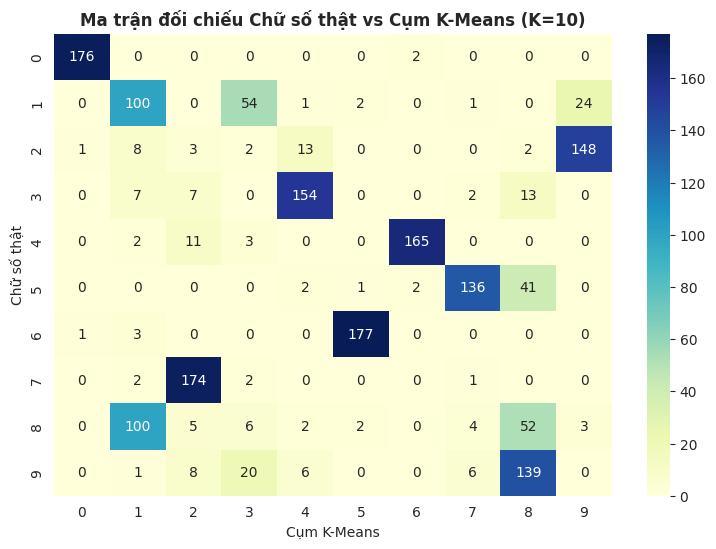

NHẬN XÉT BÀI 6:
- Các chữ số có nét đặc trưng tách biệt như số 0, 6, 4, 2 thường được gom rất gọn vào một cụm riêng.
- Các chữ số có hình dáng nét cong/thẳng tương tự nhau như (1, 8, 9) hoặc (3, 5, 8) dễ bị gom chung hoặc lẫn lộn giữa các cụm.


In [13]:
digits = load_digits()
X_dig = digits.data
nhan_that = digits.target

km_dig = KMeans(n_clusters=10, n_init=10, random_state=0).fit(X_dig)
cum_dig = km_dig.labels_

bang_cheo = pd.crosstab(nhan_that, cum_dig, rownames=['Chữ số thật'], colnames=['Cụm K-Means'])
print("Bảng đối chiếu chữ số thật và cụm K-Means:")
print(bang_cheo)

# Trực quan hóa bảng crosstab bằng Heatmap cho dễ nhìn
plt.figure(figsize=(9, 6))
sns.heatmap(bang_cheo, annot=True, fmt="d", cmap="YlGnBu")
plt.title("Ma trận đối chiếu Chữ số thật vs Cụm K-Means (K=10)", fontweight='bold')
plt.show()

print("NHẬN XÉT BÀI 6:")
print("- Các chữ số có nét đặc trưng tách biệt như số 0, 6, 4, 2 thường được gom rất gọn vào một cụm riêng.")
print("- Các chữ số có hình dáng nét cong/thẳng tương tự nhau như (1, 8, 9) hoặc (3, 5, 8) dễ bị gom chung hoặc lẫn lộn giữa các cụm.")